In [289]:
import pandas as pd
import numpy as np
import matplotlib.pyplot  as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score 
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report,confusion_matrix


In [290]:
df=pd.read_csv("hotel_bookings.csv")

In [291]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [292]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [293]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [294]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [295]:
df.duplicated().sum()

np.int64(31994)

In [296]:
df.drop_duplicates()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07


In [297]:
categorical_columns = [
    "hotel",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "assigned_room_type",
    "deposit_type",
    "customer_type"
]

for col in categorical_columns:
    if col in df.columns:
        df[col] = df[col].astype("category")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype   
---  ------                          --------------   -----   
 0   hotel                           119390 non-null  category
 1   is_canceled                     119390 non-null  int64   
 2   lead_time                       119390 non-null  int64   
 3   arrival_date_year               119390 non-null  int64   
 4   arrival_date_month              119390 non-null  str     
 5   arrival_date_week_number        119390 non-null  int64   
 6   arrival_date_day_of_month       119390 non-null  int64   
 7   stays_in_weekend_nights         119390 non-null  int64   
 8   stays_in_week_nights            119390 non-null  int64   
 9   adults                          119390 non-null  int64   
 10  children                        119386 non-null  float64 
 11  babies                          119390 non-null  int64   
 12  meal         

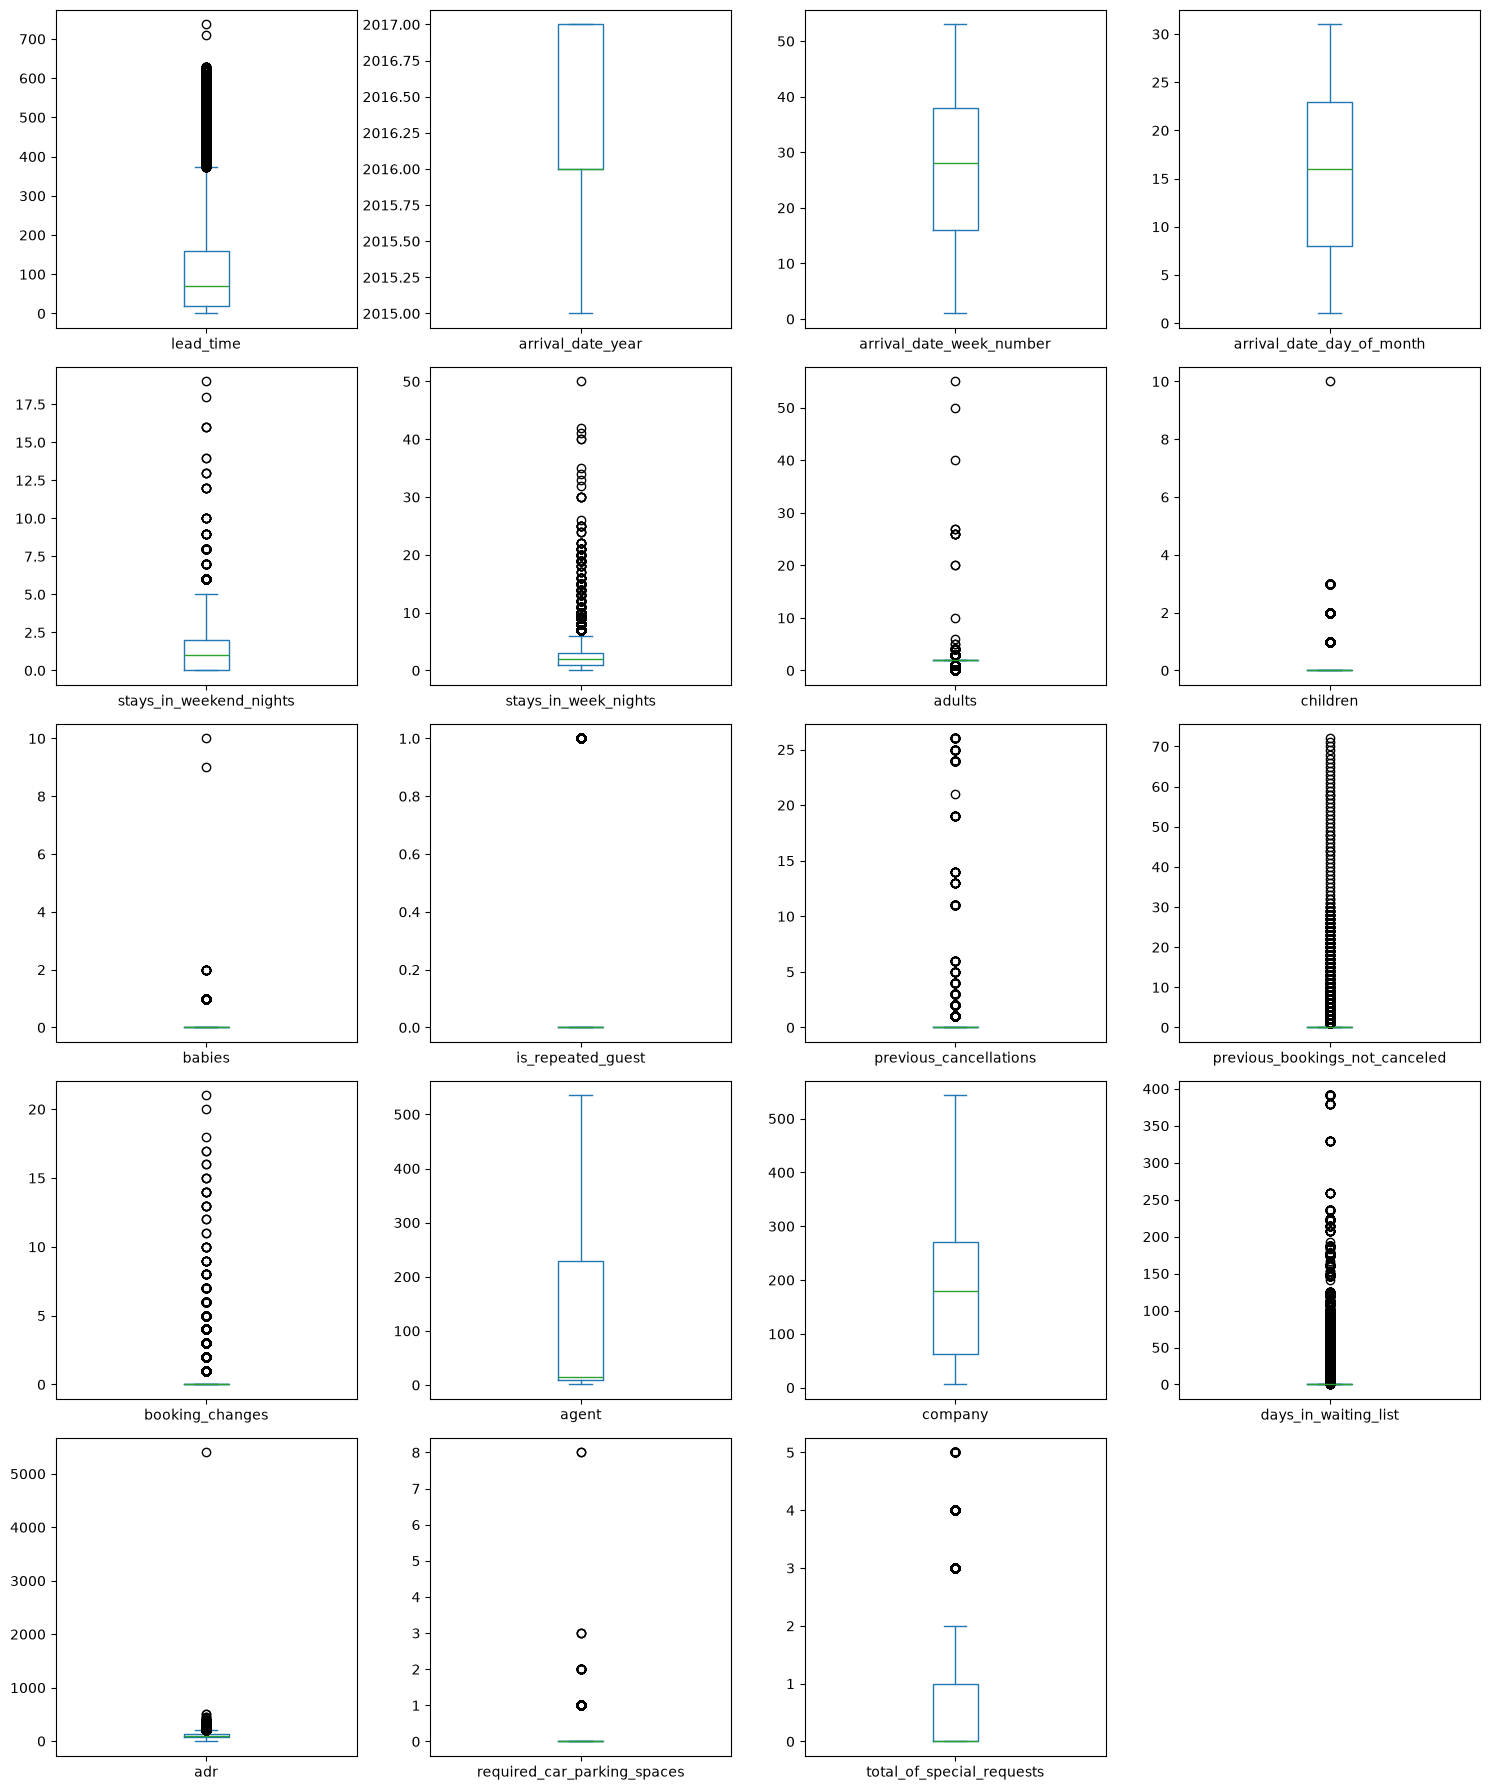

In [298]:
numeric_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

numeric_columns = [
    col for col in numeric_columns
    if col != "is_canceled"
]

df[numeric_columns].plot(
    kind="box",
    subplots=True,
    layout=(5, 4),
    figsize=(15, 18),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

In [299]:
outlier_counts = {}

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_counts[col] = count

print(
    pd.Series(outlier_counts, name="Potential Outliers")
    .sort_values(ascending=False)
)

adults                            29710
booking_changes                   18076
children                           8590
required_car_parking_spaces        7416
previous_cancellations             6484
is_repeated_guest                  3810
adr                                3793
days_in_waiting_list               3698
previous_bookings_not_canceled     3620
stays_in_week_nights               3354
lead_time                          3005
total_of_special_requests          2877
babies                              917
stays_in_weekend_nights             265
arrival_date_year                     0
arrival_date_week_number              0
arrival_date_day_of_month             0
company                               0
agent                                 0
Name: Potential Outliers, dtype: int64


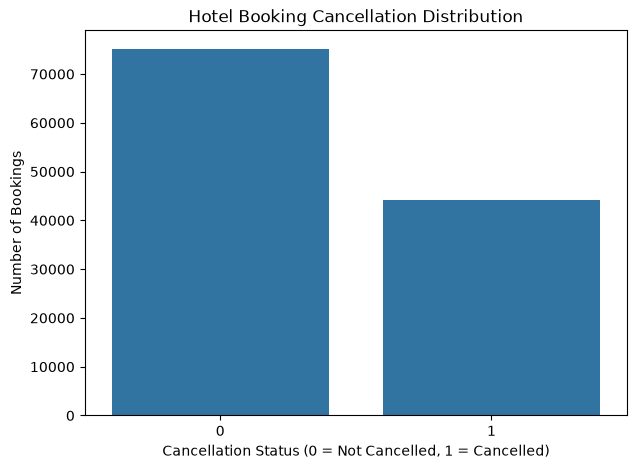

In [300]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="is_canceled")

plt.title("Hotel Booking Cancellation Distribution")
plt.xlabel("Cancellation Status (0 = Not Cancelled, 1 = Cancelled)")
plt.ylabel("Number of Bookings")

plt.show()

In [301]:
print(
    (df["is_canceled"].value_counts(normalize=True) * 100)
    .sort_index()
    .round(2)
)

is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64


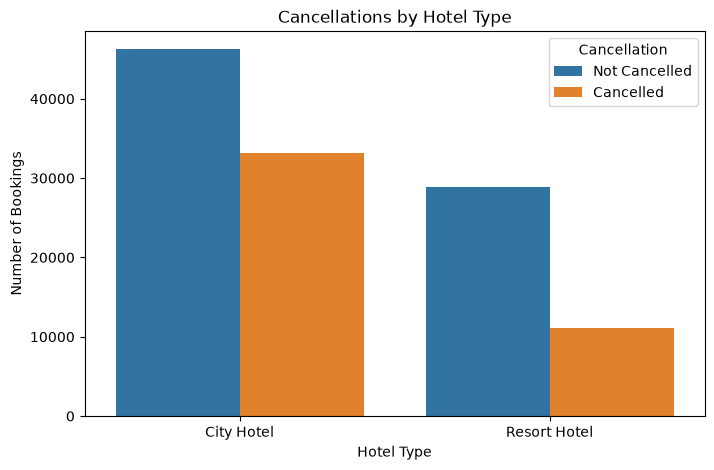

In [302]:
##cancellation
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="hotel",
    hue="is_canceled"
)

plt.title("Cancellations by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")

plt.legend(
    title="Cancellation",
    labels=["Not Cancelled", "Cancelled"]
)

plt.show()

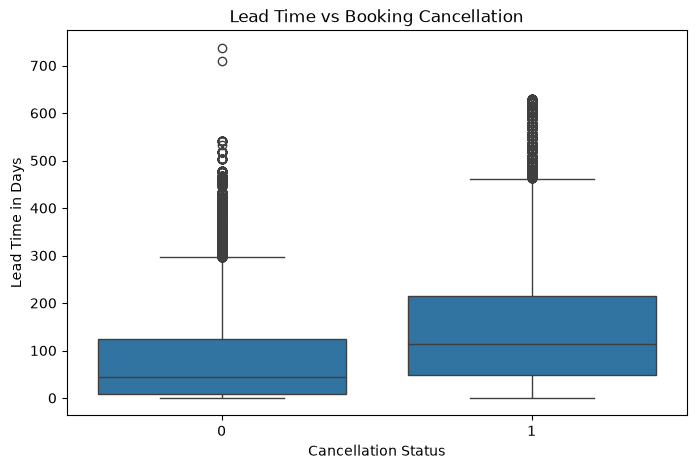

In [303]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="is_canceled",
    y="lead_time"
)

plt.title("Lead Time vs Booking Cancellation")
plt.xlabel("Cancellation Status")
plt.ylabel("Lead Time in Days")

plt.show()

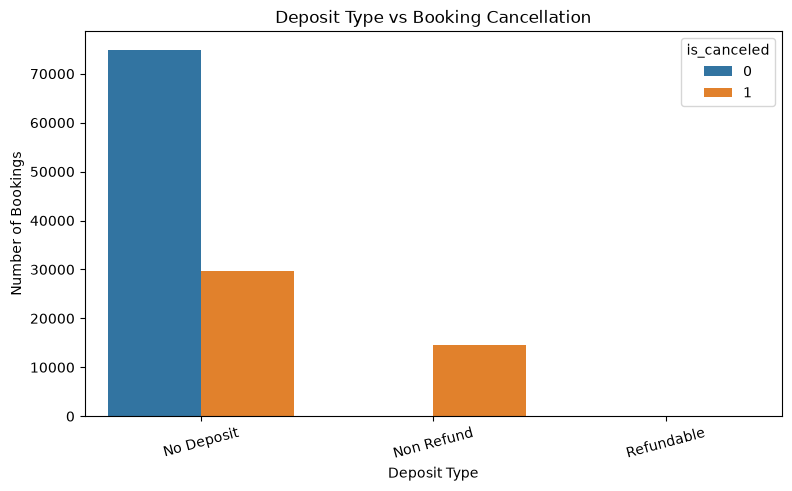

In [304]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="deposit_type",
    hue="is_canceled"
)

plt.title("Deposit Type vs Booking Cancellation")
plt.xlabel("Deposit Type")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=15)
plt.show()

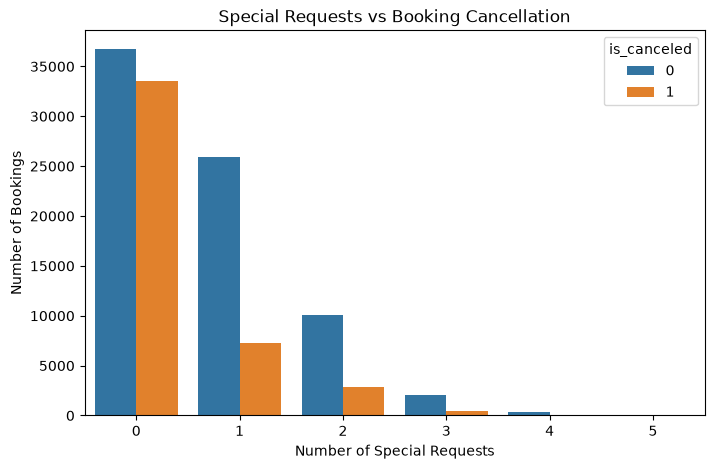

In [305]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="total_of_special_requests",
    hue="is_canceled"
)

plt.title("Special Requests vs Booking Cancellation")
plt.xlabel("Number of Special Requests")
plt.ylabel("Number of Bookings")

plt.show()

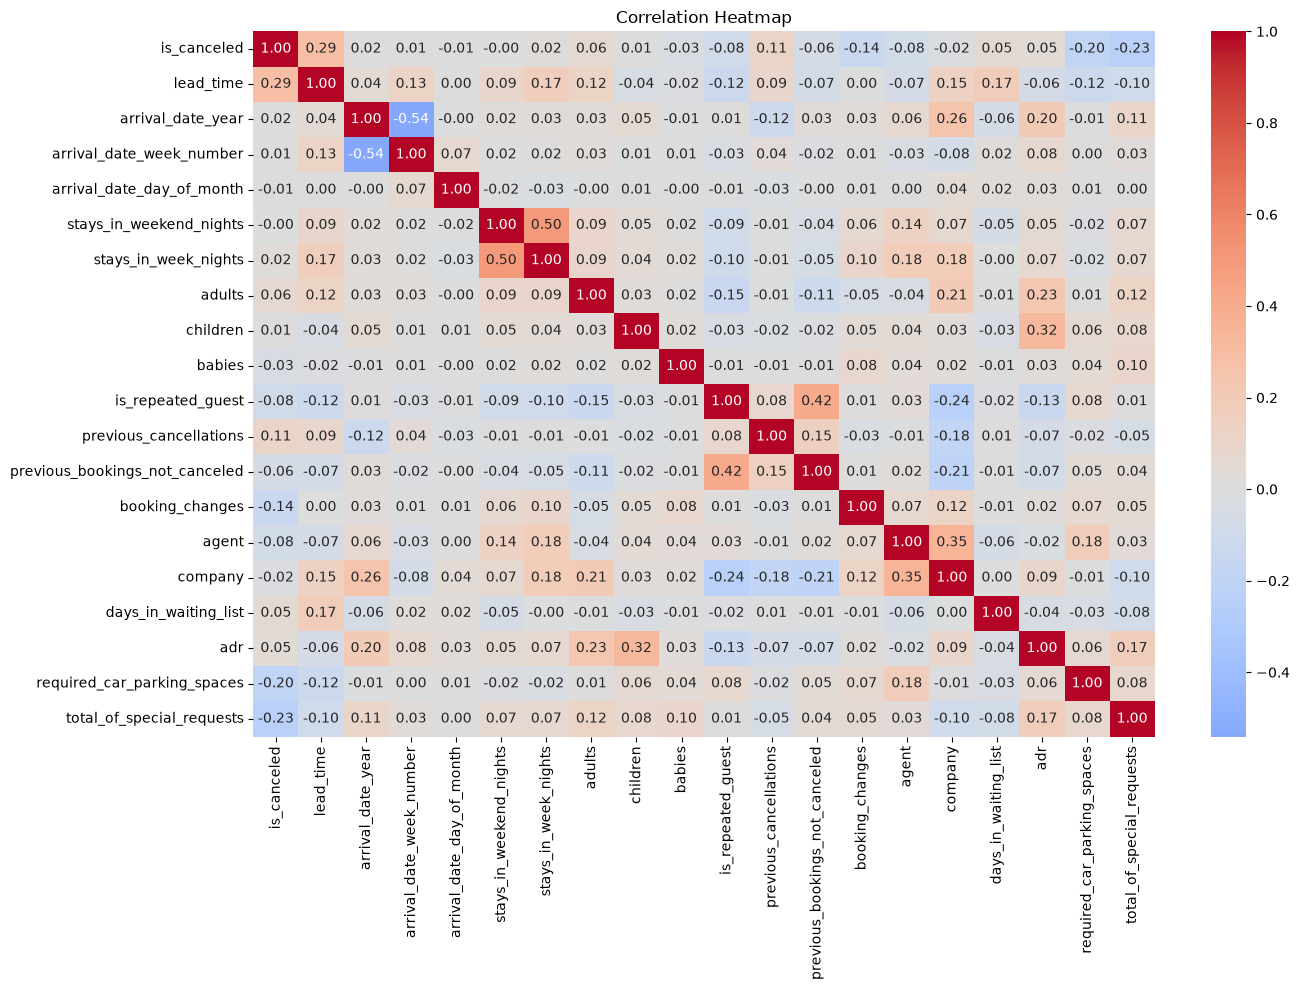

In [306]:
correlation = df.select_dtypes(
    include=["number"]
).corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [307]:
target_correlation = correlation["is_canceled"].drop(
    "is_canceled"
).sort_values(ascending=False)

print(target_correlation)

lead_time                         0.293123
previous_cancellations            0.110133
adults                            0.060017
days_in_waiting_list              0.054186
adr                               0.047557
stays_in_week_nights              0.024765
arrival_date_year                 0.016660
arrival_date_week_number          0.008148
children                          0.005048
stays_in_weekend_nights          -0.001791
arrival_date_day_of_month        -0.006130
company                          -0.020642
babies                           -0.032491
previous_bookings_not_canceled   -0.057358
agent                            -0.083114
is_repeated_guest                -0.084793
booking_changes                  -0.144381
required_car_parking_spaces      -0.195498
total_of_special_requests        -0.234658
Name: is_canceled, dtype: float64


In [308]:
columns_to_drop = [
    "reservation_status",
    "reservation_status_date",
    "company"
]

x= df.drop(
    columns=columns_to_drop,
    errors="ignore"
)

print("Features after removing leakage columns:")
print(df.columns.tolist())

Features after removing leakage columns:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


In [309]:
categorical_columns = df.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for col in categorical_columns:
    df[col] = df[col].astype("string")
    

numeric_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

print("Numerical columns:", numeric_columns)
print("\nCategorical columns:", categorical_columns)

Numerical columns: ['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Categorical columns: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


In [310]:
x = df.drop("is_canceled",axis=1)
y=df["is_canceled"]

In [311]:
x=pd.get_dummies(x,drop_first=True,dtype=int)

In [312]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (95512, 1174)
X_test: (23878, 1174)
y_train: (95512,)
y_test: (23878,)


In [313]:
type(X_train)

pandas.DataFrame

In [314]:
X_train.head()

,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,...,reservation_status_date_2017-09-03,reservation_status_date_2017-09-04,reservation_status_date_2017-09-05,reservation_status_date_2017-09-06,reservation_status_date_2017-09-07,reservation_status_date_2017-09-08,reservation_status_date_2017-09-09,reservation_status_date_2017-09-10,reservation_status_date_2017-09-12,reservation_status_date_2017-09-14
105447,20,2017,6,7,0,2,1,0.0,0,0,...,0,0,0,0,0,0,0,0,0,0
85242,8,2016,11,9,0,3,2,0.0,0,0,...,0,0,0,0,0,0,0,0,0,0
65604,93,2017,14,6,0,3,2,0.0,0,0,...,0,0,0,0,0,0,0,0,0,0
17345,90,2015,39,23,4,10,2,0.0,0,0,...,0,0,0,0,0,0,0,0,0,0
117786,8,2017,32,9,0,1,1,0.0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [315]:

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_columns),
        (
            "cat",
            categorical_transformer,
            categorical_columns
        )
    ]
)

print("Preprocessing pipeline created successfully")

Preprocessing pipeline created successfully


In [316]:
print("Missing numerical columns:", set(numeric_columns) - set(X_train.columns))
print("Missing categorical columns:", set(categorical_columns) - set(X_train.columns))

Missing numerical columns: {'is_canceled'}
Missing categorical columns: {'customer_type', 'market_segment', 'country', 'hotel', 'reserved_room_type', 'arrival_date_month', 'reservation_status', 'distribution_channel', 'reservation_status_date', 'assigned_room_type', 'meal', 'deposit_type'}


In [317]:
numeric_columns = [col for col in numeric_columns if col in X_train.columns]

categorical_columns = [col for col in categorical_columns if col in X_train.columns]

In [318]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_columns),
        ("cat", categorical_transformer, categorical_columns)
    ]
)

In [319]:
print("Target variable: is_canceled")
print("Problem type: Binary Classification")
print("Class 0: Booking not cancelled")
print("Class 1: Booking cancelled")

Target variable: is_canceled
Problem type: Binary Classification
Class 0: Booking not cancelled
Class 1: Booking cancelled


In [320]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=10,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_split=10,
        n_jobs=-1,
        random_state=42
    )
}

In [321]:
type(X_train)

pandas.DataFrame

In [322]:
X_train.shape

(95512, 1174)

In [323]:
results = []
trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train,y_train)

    y_train_pred = pipeline.predict(X_train)
    y_test_pred = pipeline.predict(X_test)

    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    results.append({
        "Model": name,
        "Training Accuracy": train_accuracy,
        "Testing Accuracy": test_accuracy
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)

results_df

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...


,Model,Training Accuracy,Testing Accuracy
0,Logistic Regression,0.737331,0.738462
1,Decision Tree,0.790079,0.786959
2,Random Forest,0.838062,0.824315


In [324]:
results_df.columns.tolist()

['Model', 'Training Accuracy', 'Testing Accuracy']

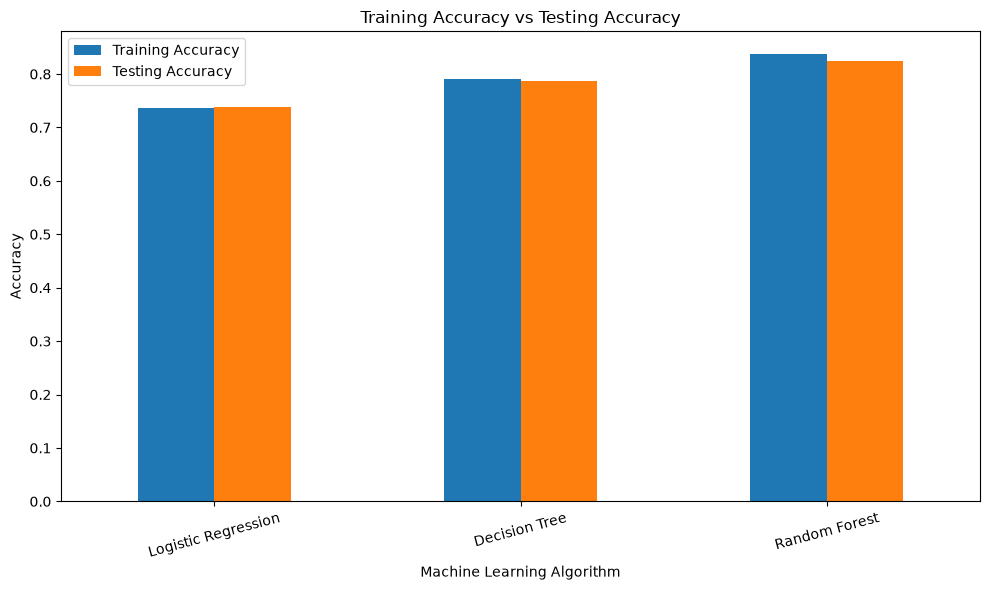

In [325]:
results_df.set_index("Model")[
    ["Training Accuracy","Testing Accuracy"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Training Accuracy vs Testing Accuracy")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("Accuracy")
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()

In [326]:
results = []
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_train_pred = pipeline.predict(X_train)
    y_test_pred = pipeline.predict(X_test)

    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    test_f1 = f1_score(y_test, y_test_pred)

    results.append({
        "Model": name,
        "Training Accuracy": train_accuracy,
        "Testing Accuracy": test_accuracy,
        "Test F1 Score": test_f1
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)

results_df

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...


,Model,Training Accuracy,Testing Accuracy,Test F1 Score
0,Logistic Regression,0.737331,0.738462,0.585793
1,Decision Tree,0.790079,0.786959,0.698655
2,Random Forest,0.838062,0.824315,0.737172


In [327]:
results_df= pd.DataFrame(results)
results_df

,Model,Training Accuracy,Testing Accuracy,Test F1 Score
0,Logistic Regression,0.737331,0.738462,0.585793
1,Decision Tree,0.790079,0.786959,0.698655
2,Random Forest,0.838062,0.824315,0.737172


In [328]:
results_df.columns

Index(['Model', 'Training Accuracy', 'Testing Accuracy', 'Test F1 Score'], dtype='str')

In [329]:
results_df

,Model,Training Accuracy,Testing Accuracy,Test F1 Score
0,Logistic Regression,0.737331,0.738462,0.585793
1,Decision Tree,0.790079,0.786959,0.698655
2,Random Forest,0.838062,0.824315,0.737172


In [330]:
best_model_name = results_df.loc[
    results_df["Test F1 Score"].idxmax(),
    "Model"
]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("Best F1 Score:", results_df["Test F1 Score"].max())

Best Model: Random Forest
Best F1 Score: 0.737171856399975


In [331]:
X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=x.columns
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=x.columns
)

In [332]:
y_pred = best_model.predict(X_test)

print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Not Cancelled",
            "Cancelled"
        ],
        zero_division=0
    )
)

Classification Report:

               precision    recall  f1-score   support

Not Cancelled       0.82      0.92      0.87     15033
    Cancelled       0.83      0.67      0.74      8845

     accuracy                           0.82     23878
    macro avg       0.83      0.79      0.80     23878
 weighted avg       0.82      0.82      0.82     23878



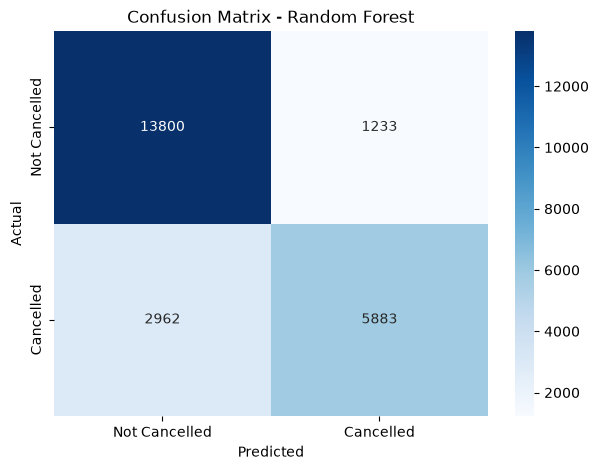

In [333]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Not Cancelled",
        "Cancelled"
    ],
    yticklabels=[
        "Not Cancelled",
        "Cancelled"
    ]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [334]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("Best Model:", best_model_name)
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

Best Model: Random Forest
Accuracy: 0.8243
Precision: 0.8267
Recall: 0.6651
F1 Score: 0.7372


In [335]:
print("=" * 50)
print("HOTEL BOOKING CANCELLATION PROJECT")
print("=" * 50)

print("\nProblem Type: Binary Classification")

print("\nAlgorithms Compared:")
for name in models.keys():
    print("-", name)

print("\nBest Algorithm:", best_model_name)

print("Test Accuracy:", round(accuracy, 4))
print("Test Precision:", round(precision, 4))
print("Test Recall:", round(recall, 4))
print("Test F1 Score:", round(f1, 4))

print("\nConclusion:")
print(
    "The models were compared using their training and "
    "testing performance. The model with the highest "
    "test F1-score was selected as the initial best model."
)

print(
    "The hotel can use cancellation predictions to help "
    "prioritise bookings for follow-up and revenue management."
)

HOTEL BOOKING CANCELLATION PROJECT

Problem Type: Binary Classification

Algorithms Compared:
- Logistic Regression
- Decision Tree
- Random Forest

Best Algorithm: Random Forest
Test Accuracy: 0.8243
Test Precision: 0.8267
Test Recall: 0.6651
Test F1 Score: 0.7372

Conclusion:
The models were compared using their training and testing performance. The model with the highest test F1-score was selected as the initial best model.
The hotel can use cancellation predictions to help prioritise bookings for follow-up and revenue management.
